# Module 18 — Exercises — Solutions

These exercises follow the order of the concept guide: exact samplers, rejection and importance sampling,
Markov chains, Metropolis–Hastings, the VAE's Gaussian KL, the diffusion forward process and the score, and
finally a Bayesian mini-project with MCMC. Several checks compare against *hidden* values of seeded
computations, so follow the specified recipe (which `rng` call, in which order) exactly.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Exact samplers: inverse CDF and cumulative sums  `★☆☆`

Implement two samplers that use **only** `rng.random` (uniforms) plus NumPy arithmetic — no
`rng.exponential`, no `rng.choice`:

* `sample_exponential(lam, n, rng)` → array of `n` draws from Exponential($\lambda$) via the inverse CDF
  $X = -\ln(1 - U)/\lambda$, where `U = rng.random(n)` is drawn **once, in that form**;
* `sample_discrete(p, n, rng)` → array of `n` integer category indices for probabilities `p`, obtained
  by drawing `U = rng.random(n)` and returning the smallest `k` with `cumsum(p)[k] >= U`
  (`np.searchsorted` on the cumulative sums does exactly this).

Because the checks reproduce your draws with a fixed seed, use exactly one call `rng.random(n)` in each function.

In [3]:
def sample_exponential(lam, n, rng):
    u = rng.random(n)
    return -np.log(1 - u) / lam

def sample_discrete(p, n, rng):
    cdf = np.cumsum(np.asarray(p, dtype=float))
    u = rng.random(n)
    return np.searchsorted(cdf, u)

**Check your answer:**

In [4]:
try:
    xs = sample_exponential(2.0, 50_000, np.random.default_rng(1))
    m, v = float(np.mean(xs)), float(np.var(xs))
except Exception:
    xs, m, v = None, None, None
check('Exponential(2): sample mean within 2% of 1/2', m is not None and abs(m - 0.5) < 0.01)
check('Exponential(2): sample variance within 5% of 1/4', v is not None and abs(v - 0.25) < 0.0125)
check('Exponential(2): all samples positive', xs is not None and bool(np.all(np.asarray(xs) > 0)))
try:
    got = np.round(sample_exponential(2.0, 3, np.random.default_rng(7)), 4)
except Exception:
    got = None
check_hash('hidden: the first three Exponential(2) draws with seed 7', got, '8ec82f644f048596', decimals=4)
try:
    ks = np.asarray(sample_discrete([0.2, 0.5, 0.3], 50_000, np.random.default_rng(2)))
    freq = np.bincount(ks, minlength=3) / len(ks)
except Exception:
    ks, freq = None, None
check('discrete sampler: frequencies within 0.01 of p', freq is not None and bool(np.all(np.abs(freq - np.array([0.2, 0.5, 0.3])) < 0.01)))
check('discrete sampler returns integer indices in {0, 1, 2}', ks is not None and set(np.unique(ks).tolist()) <= {0, 1, 2})
try:
    got = np.asarray(sample_discrete([0.1, 0.2, 0.3, 0.4], 5, np.random.default_rng(7))).astype(int)
except Exception:
    got = None
check_hash('hidden: five categorical draws with seed 7', got, '0458632f0afa9a38')

✅ Exponential(2): sample mean within 2% of 1/2
✅ Exponential(2): sample variance within 5% of 1/4
✅ Exponential(2): all samples positive
✅ hidden: the first three Exponential(2) draws with seed 7
✅ discrete sampler: frequencies within 0.01 of p
✅ discrete sampler returns integer indices in {0, 1, 2}
✅ hidden: five categorical draws with seed 7


True

**Why this works**

If $U$ is uniform then $P(F^{-1}(U) \le x) = P(U \le F(x)) = F(x)$, so $X = F^{-1}(U)$ has CDF $F$; for the
Exponential, $F(x) = 1 - e^{-\lambda x}$ inverts to $-\ln(1 - u)/\lambda$. The discrete version is the same
statement for a step CDF: the interval $(c_{k-1}, c_k]$ has length $p_k$, so `searchsorted` returns category
$k$ with probability $p_k$. The common wrong turn is `np.searchsorted(cdf, u, side='right')`, which differs
from the default only on the measure-zero event $U = c_k$ but would change the hidden hash if it did occur;
another is using `rng.random()` inside a Python loop, which changes the order of draws.

## Exercise 2 — Rejection sampling for Beta(2, 5)  `★☆☆`

The Beta(2, 5) density is $p(x) = 30\,x(1-x)^4$ on $[0, 1]$; its maximum is at $x^* = 0.2$. Implement

* `beta25_pdf(x)` — the density (vectorised);
* `rejection_beta25(n_proposals, rng)` — rejection sampling with the uniform proposal $q = \text{Uniform}(0,1)$
  and the **tightest** valid envelope constant $M = p(0.2)$. Draw `x = rng.random(n_proposals)` first, then
  `u = rng.random(n_proposals)`, accept where `u <= p(x) / M`, and return the tuple
  `(accepted_samples, acceptance_rate)` with the rate as a float.

Only NumPy; do not use `scipy.stats.beta` to generate samples.

In [5]:
def beta25_pdf(x):
    return 30 * x * (1 - x) ** 4

def rejection_beta25(n_proposals, rng):
    M = beta25_pdf(0.2)
    x = rng.random(n_proposals)
    u = rng.random(n_proposals)
    keep = u <= beta25_pdf(x) / M
    return x[keep], float(keep.mean())

**Check your answer:**

In [6]:
try:
    got = float(beta25_pdf(0.2))
except Exception:
    got = None
check_close('density at the mode p(0.2) = 2.4576', got, 2.4576, tol=1e-9)
try:
    got = float(beta25_pdf(0.5))
except Exception:
    got = None
check_close('density at 0.5 agrees with scipy', got, float(stats.beta.pdf(0.5, 2, 5)), tol=1e-9)
try:
    samples, rate = rejection_beta25(200_000, np.random.default_rng(3))
    samples = np.asarray(samples, dtype=float); rate = float(rate)
except Exception:
    samples, rate = None, None
check('acceptance rate within 0.01 of 1/M = 0.4069', rate is not None and abs(rate - 1 / 2.4576) < 0.01)
check('number of accepted samples matches the rate', samples is not None and abs(len(samples) - rate * 200_000) < 1)
check('accepted samples have mean within 0.01 of 2/7', samples is not None and abs(samples.mean() - 2 / 7) < 0.01)
check('accepted samples have variance within 10% of 10/392', samples is not None and abs(samples.var() - 10 / 392) < 0.1 * 10 / 392)
check_hash('hidden: exact acceptance rate for seed 3', (round(rate, 4) if rate is not None else None), '5d4e93def6fb391c', decimals=4)

✅ density at the mode p(0.2) = 2.4576
✅ density at 0.5 agrees with scipy
✅ acceptance rate within 0.01 of 1/M = 0.4069
✅ number of accepted samples matches the rate
✅ accepted samples have mean within 0.01 of 2/7
✅ accepted samples have variance within 10% of 10/392
✅ hidden: exact acceptance rate for seed 3


True

**Why this works**

With a uniform proposal the envelope is a flat line at height $M$, and the tightest choice is the maximum
of the target: $p'(x) = 30(1-x)^3(1 - 5x) = 0$ at $x = 0.2$, $M = 2.4576$. Accepted points are uniform under
the curve $p$, so their $x$-coordinates have density $p$ exactly, and the fraction accepted is the area
under $p$ (one) over the area under the envelope ($M$), i.e. $1/M \approx 40.7\%$. A larger $M$ would still
be *valid* (the samples stay exactly Beta-distributed) but wasteful; a smaller one is *invalid* and clips the
density near the mode — the acceptance check `u <= p/M` would then saturate at 1 there.

## Exercise 3 — Importance sampling for a Gaussian tail probability  `★★☆`

Estimate $\mu = P(X > a)$ for $X \sim \mathcal{N}(0, 1)$ with importance sampling from the shifted proposal
$q = \mathcal{N}(\text{shift}, 1)$. Implement

* `is_tail_estimate(a, n, shift, rng)` → the tuple `(estimate, fw)`, where the samples are
  `x = rng.normal(shift, 1.0, n)`, the weights are $w(x) = \phi(x)/\phi(x - \text{shift})$ (compute them from
  the formula $\exp\!\big(-x^2/2 + (x - \text{shift})^2/2\big)$ or with `scipy.stats.norm.pdf`), `fw` is the
  array of the $n$ weighted integrands $\mathbf{1}[x_i > a]\,w(x_i)$, and `estimate` is `fw.mean()` as a float;
* `effective_sample_size(w)` → $(\sum_i w_i)^2 / \sum_i w_i^2$ as a float.

Test case: `a = 4`, `n = 20_000`, `shift = 4`, `rng = np.random.default_rng(5)`; the truth is `stats.norm.sf(4)`.

In [7]:
def is_tail_estimate(a, n, shift, rng):
    x = rng.normal(shift, 1.0, n)                     # proposal N(shift, 1)
    w = np.exp(-0.5 * x ** 2 + 0.5 * (x - shift) ** 2)   # phi(x) / phi(x - shift)
    fw = (x > a) * w
    return float(fw.mean()), fw

def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    return float(w.sum() ** 2 / (w ** 2).sum())

**Check your answer:**

In [8]:
truth = stats.norm.sf(4.0)
try:
    est, fw = is_tail_estimate(4.0, 20_000, 4.0, np.random.default_rng(5))
    est = float(est); fw = np.asarray(fw, dtype=float)
except Exception:
    est, fw = None, None
check('IS estimate of P(X > 4) within 5% of the truth', est is not None and abs(est - truth) / truth < 0.05)
check('fw has one entry per proposal and is zero where x <= 4 (about half of them)', fw is not None and fw.shape == (20_000,) and 0.4 < np.mean(fw == 0) < 0.6)
check_hash('hidden: the estimate for seed 5 (rounded to 7 decimals)', (round(est, 7) if est is not None else None), '19d2ac0cbe4f9d51', decimals=7)
try:
    got = effective_sample_size([0.1, 0.1, 0.1, 0.7])
except Exception:
    got = None
check_close('ESS of weights (0.1, 0.1, 0.1, 0.7) is 1/0.52', got, 1 / 0.52)
try:
    got = effective_sample_size(np.ones(50))
except Exception:
    got = None
check_close('ESS of 50 equal weights is 50', got, 50.0)
try:
    e = effective_sample_size(fw)
except Exception:
    e = None
check('ESS of the weighted integrands is between 3,000 and 4,500 (about 18% of n)', e is not None and 3_000 < e < 4_500)
try:
    e3 = effective_sample_size(is_tail_estimate(4.0, 20_000, 3.0, np.random.default_rng(5))[1])
    e5 = effective_sample_size(is_tail_estimate(4.0, 20_000, 5.0, np.random.default_rng(5))[1])
except Exception:
    e3, e5 = None, None
check('shifting the proposal to 3 or to 5 lowers the ESS compared with 4', e is not None and e3 is not None and e5 is not None and e3 < e and e5 < e)

✅ IS estimate of P(X > 4) within 5% of the truth
✅ fw has one entry per proposal and is zero where x <= 4 (about half of them)
✅ hidden: the estimate for seed 5 (rounded to 7 decimals)
✅ ESS of weights (0.1, 0.1, 0.1, 0.7) is 1/0.52
✅ ESS of 50 equal weights is 50
✅ ESS of the weighted integrands is between 3,000 and 4,500 (about 18% of n)
✅ shifting the proposal to 3 or to 5 lowers the ESS compared with 4


True

**Why this works**

The identity $\mathbb{E}_p[f] = \mathbb{E}_q[f\,p/q]$ makes the weighted average unbiased for any $q$ that
covers the tail. Shifting the proposal to the boundary puts half the samples where the indicator is 1, and
their weights $e^{8 - 4x}$ are at most $e^{-8}$, so the variance per sample drops by a factor of several
thousand relative to plain Monte Carlo (which expects 0.6 hits in 20,000 draws). The ESS of the weighted
integrands is about 18% of $n$ — the theoretical value is $\mu^2/(e^{16}\Phi(-8)) \approx 0.18$ — and it is
*lower* for shifts of 3 (too few samples in the tail) or 5 (weights become more variable), so the ESS is
also a tool for choosing the proposal. The typical error is to compute the ESS of the raw weights $w$ rather
than of $f \cdot w$: for this problem the raw ESS is tiny (about 9) because the weights are huge where
$x < 4$, yet those samples do not matter since the indicator kills them.

## Exercise 4 — Stationary distributions and detailed balance  `★★☆`

Implement

* `stationary_distribution(P)` → the stationary distribution $\pi$ of the row-stochastic matrix `P`, solving
  $\pi = \pi P$ (hint: $\pi^\top$ is the eigenvector of $P^\top$ with eigenvalue 1; take the real part and
  normalise so the entries sum to 1), returned as a 1-D NumPy array;
* `satisfies_detailed_balance(P, pi, tol=1e-9)` → `True` if $\pi_i P_{ij} = \pi_j P_{ji}$ for all $i, j$
  (to tolerance `tol`), else `False`.

Test chains: the weather chain of the guide
`[[0.7, 0.2, 0.1], [0.3, 0.4, 0.3], [0.2, 0.3, 0.5]]`; the birth–death chain
`[[0.5, 0.5, 0], [0.25, 0.5, 0.25], [0, 0.5, 0.5]]`; and the cyclic chain
`[[0.1, 0.9, 0], [0, 0.1, 0.9], [0.9, 0, 0.1]]`.

In [9]:
def stationary_distribution(P):
    P = np.asarray(P, dtype=float)
    evals, evecs = np.linalg.eig(P.T)
    k = np.argmin(np.abs(evals - 1.0))
    pi = np.real(evecs[:, k])
    pi = pi / pi.sum()
    return pi

def satisfies_detailed_balance(P, pi, tol=1e-9):
    P = np.asarray(P, dtype=float); pi = np.asarray(pi, dtype=float)
    flows = pi[:, None] * P
    return bool(np.allclose(flows, flows.T, atol=tol))

**Check your answer:**

In [10]:
P_w = np.array([[0.7, 0.2, 0.1], [0.3, 0.4, 0.3], [0.2, 0.3, 0.5]])
P_q = np.array([[0.5, 0.5, 0.0], [0.25, 0.5, 0.25], [0.0, 0.5, 0.5]])
P_c = np.array([[0.1, 0.9, 0.0], [0.0, 0.1, 0.9], [0.9, 0.0, 0.1]])
try:
    pi_w = np.asarray(stationary_distribution(P_w), dtype=float).reshape(3)
except Exception:
    pi_w = None
check_close('weather chain: pi = (21, 13, 12)/46', pi_w, np.array([21, 13, 12]) / 46, tol=1e-6)
check_close('weather chain: pi P = pi', (pi_w @ P_w if pi_w is not None else None), pi_w, tol=1e-9)
try:
    pi_q = np.asarray(stationary_distribution(P_q), dtype=float).reshape(3)
except Exception:
    pi_q = None
check_hash('hidden: stationary distribution of the birth-death chain', (np.round(pi_q, 4) if pi_q is not None else None), 'f30b0b07dc722f68', decimals=4)
try:
    pi_c = np.asarray(stationary_distribution(P_c), dtype=float).reshape(3)
except Exception:
    pi_c = None
check_close('cyclic chain: uniform stationary distribution', pi_c, np.ones(3) / 3, tol=1e-6)
try:
    db = [bool(satisfies_detailed_balance(P, pi)) for P, pi in ((P_w, pi_w), (P_q, pi_q), (P_c, pi_c))]
except Exception:
    db = None
check('detailed balance: weather False, birth-death True, cyclic False', db == [False, True, False])
try:
    got = satisfies_detailed_balance(np.eye(2), np.array([0.3, 0.7]))
except Exception:
    got = None
check('the identity chain satisfies detailed balance for any pi', got is True)

✅ weather chain: pi = (21, 13, 12)/46
✅ weather chain: pi P = pi
✅ hidden: stationary distribution of the birth-death chain
✅ cyclic chain: uniform stationary distribution
✅ detailed balance: weather False, birth-death True, cyclic False
✅ the identity chain satisfies detailed balance for any pi


True

**Why this works**

$\pi = \pi P$ is $P^\top\pi^\top = \pi^\top$, an eigenvector problem; `np.linalg.eig` may return the vector
with an arbitrary sign and complex dtype, hence the real part and the normalisation. All three chains have
a unique stationary distribution (they are irreducible and aperiodic), but only the birth–death chain
satisfies $\pi_i P_{ij} = \pi_j P_{ji}$: for the cyclic chain probability flows around the cycle
($\pi_1 P_{12} = 0.3$ but $\pi_2 P_{21} = 0$), and for the weather chain the flows are merely unequal
($0.0913$ vs $0.0848$). Detailed balance is sufficient for stationarity, which is why MCMC algorithms impose
it, but it is not necessary — a common confusion.

## Exercise 5 — Random-walk Metropolis–Hastings for a Gamma target  `★★☆`

The target is Gamma(shape 3, rate 1), known only up to a constant: $\log\tilde p(x) = 2\ln x - x$ for $x > 0$
and $-\infty$ otherwise. Implement

* `log_gamma3(x)` — the unnormalised log density for a scalar `x` (return `-np.inf` for `x <= 0`);
* `acceptance_probability(log_target, x, prop)` → $\min\{1, \tilde p(\text{prop})/\tilde p(x)\}$ for a symmetric
  proposal, computed from the log target;
* `random_walk_mh(log_target, x0, step, n, rng)` → `(chain, acceptance_rate)`: `n` iterations starting from
  `x0`; at each iteration draw `prop = x + step * rng.standard_normal()`, then `u = rng.random()`, accept
  if `np.log(u) < log_target(prop) - log_target(x)`, and record the current state (whether or not the move was
  accepted) in a NumPy array of length `n`. Exactly these two `rng` calls per iteration, in this order.

Test: `random_walk_mh(log_gamma3, 3.0, 2.5, 30_000, np.random.default_rng(11))`, discarding the first 2,000
samples as burn-in. Gamma(3, 1) has mean 3 and variance 3.

In [11]:
def log_gamma3(x):
    return 2 * np.log(x) - x if x > 0 else -np.inf

def random_walk_mh(log_target, x0, step, n, rng):
    x = float(x0)
    lp = log_target(x)
    chain = np.empty(n)
    n_acc = 0
    for i in range(n):
        prop = x + step * rng.standard_normal()
        lp_prop = log_target(prop)
        if np.log(rng.random()) < lp_prop - lp:
            x, lp = prop, lp_prop
            n_acc += 1
        chain[i] = x
    return chain, n_acc / n

def acceptance_probability(log_target, x, prop):
    return float(min(1.0, np.exp(log_target(prop) - log_target(x))))

**Check your answer:**

In [12]:
try:
    got = [float(log_gamma3(1.0)), float(log_gamma3(2.0)), float(log_gamma3(-1.0))]
    ok_log = abs(got[0] + 1) < 1e-12 and abs(got[1] - (2 * np.log(2) - 2)) < 1e-12 and got[2] == -np.inf
except Exception:
    ok_log = False
check('log target: log p(1) = -1, log p(2) = 2 ln 2 - 2, log p(-1) = -inf', ok_log)
try:
    a1 = acceptance_probability(log_gamma3, 1.0, 2.0)
    a2 = acceptance_probability(log_gamma3, 2.0, 3.0)
    a3 = acceptance_probability(log_gamma3, 2.0, 6.0)
except Exception:
    a1 = a2 = a3 = None
check_close('uphill move 1 -> 2 (towards the mode at 2) is accepted with probability 1', a1, 1.0)
check_hash('hidden: acceptance probability of the downhill move 2 -> 3', (round(a2, 6) if a2 is not None else None), 'd8a4eda59292fe75', decimals=6)
check_hash('hidden: acceptance probability of the downhill move 2 -> 6', (round(a3, 6) if a3 is not None else None), '1cd877705cdc9115', decimals=6)
try:
    chain, rate = random_walk_mh(log_gamma3, 3.0, 2.5, 30_000, np.random.default_rng(11))
    chain = np.asarray(chain, dtype=float); rate = float(rate); post = chain[2000:]
except Exception:
    chain, rate, post = None, None, None
check('chain has length 30,000 and stays positive', chain is not None and chain.shape == (30_000,) and bool(np.all(chain > 0)))
check('acceptance rate between 0.45 and 0.65 for step 2.5', rate is not None and 0.45 < rate < 0.65)
check('posterior mean within 0.1 of 3', post is not None and abs(post.mean() - 3) < 0.1)
check('posterior variance within 0.3 of 3', post is not None and abs(post.var() - 3) < 0.3)
check_hash('hidden: exact acceptance rate for seed 11, step 2.5', (round(rate, 4) if rate is not None else None), 'b66fa6065864db1b', decimals=4)
try:
    rate_small = random_walk_mh(log_gamma3, 3.0, 0.3, 30_000, np.random.default_rng(11))[1]
    rate_large = random_walk_mh(log_gamma3, 3.0, 12.0, 30_000, np.random.default_rng(11))[1]
except Exception:
    rate_small = rate_large = None
check('tiny step accepts > 85%, huge step accepts < 25%', rate_small is not None and rate_large is not None and rate_small > 0.85 and rate_large < 0.25)

✅ log target: log p(1) = -1, log p(2) = 2 ln 2 - 2, log p(-1) = -inf
✅ uphill move 1 -> 2 (towards the mode at 2) is accepted with probability 1
✅ hidden: acceptance probability of the downhill move 2 -> 3
✅ hidden: acceptance probability of the downhill move 2 -> 6
✅ chain has length 30,000 and stays positive
✅ acceptance rate between 0.45 and 0.65 for step 2.5
✅ posterior mean within 0.1 of 3
✅ posterior variance within 0.3 of 3
✅ hidden: exact acceptance rate for seed 11, step 2.5


✅ tiny step accepts > 85%, huge step accepts < 25%


True

**Why this works**

Only *ratios* of the target enter, so the Gamma normalising constant $1/\Gamma(3) = 1/2$ never has to be known,
and working with $\log\tilde p$ keeps the comparison `log(u) < log p(prop) - log p(x)` safe from under- and
overflow. A proposal below zero has $\log\tilde p = -\infty$ and is rejected automatically. The step $2.5$
(about 1.4 target standard deviations) gives an acceptance rate near 0.55 and a chain whose mean and variance
match Gamma(3, 1) after burn-in; the step $0.3$ accepts almost everything but moves slowly, and the step $12$
is rejected most of the time. Recording the *current* state after a rejection — not skipping it — is
essential: the repeated values are what give low-density regions their correct (small) weight.

## Exercise 6 — Dimension kills rejection sampling; the direction of the KL matters  `★★☆`

1. A colleague proposes to sample a 200-dimensional posterior by rejection sampling with a Gaussian proposal
   whose covariance is "about right, within 10% in each direction". Estimate the acceptance rate and explain
   why no amount of tuning will save the plan.
2. Variational inference minimises $\text{KL}(q \,\|\, p)$ (reverse KL). Suppose the true posterior $p$ is a
   50/50 mixture of two well-separated Gaussians and $q$ is a single Gaussian. Describe the $q$ that minimises
   the reverse KL and the $q$ that would minimise the forward KL $\text{KL}(p \,\|\, q)$, and explain why VI
   uses the reverse direction anyway.

**Answer**

1. For target $\mathcal{N}(0, I_d)$ and proposal $\mathcal{N}(0, \sigma^2 I_d)$ with $\sigma = 1.1$ (the proposal
   must be *wider* than the target or no finite envelope exists), the tightest constant is
   $M = \sup_x p(x)/q(x) = \sigma^d$, so the acceptance rate is $\sigma^{-d} = 1.1^{-200} \approx 5 \times 10^{-9}$
   — one accepted sample per 200 million proposals. The failure is structural: a per-coordinate mismatch of
   $\sigma$ becomes $\sigma^d$ in the density ratio, and even $\sigma = 1.01$ gives $1.01^{-200} \approx 0.14$ only
   because the proposal is then essentially the target, which we cannot construct without already knowing the
   posterior. Any error in the proposal is amplified exponentially in $d$, which is why high-dimensional
   sampling uses Markov chains (local moves, no global envelope) or variational methods.
2. The reverse KL $\text{KL}(q \,\|\, p) = \mathbb{E}_q[\log q - \log p]$ is huge wherever $q$ puts mass but $p$ is
   tiny, so the optimal single Gaussian sits on *one* of the two modes, matching its width (**mode-seeking**,
   variance underestimated: it ignores half the posterior). The forward KL $\text{KL}(p \,\|\, q) = \mathbb{E}_p[\log p - \log q]$
   penalises $q$ wherever $p$ has mass and $q$ does not, so its minimiser is a broad Gaussian covering both modes
   with the correct overall mean and inflated variance (**mass-covering**). VI uses the reverse direction because
   its expectation is under $q$, which we can sample and differentiate through, and because it leads to the
   ELBO, which needs only the unnormalised $p(x, z)$; the forward KL requires expectations under the unknown
   posterior — the very thing we are trying to compute.

## Exercise 7 — The VAE's closed-form KL, verified by Monte Carlo  `★★☆`

For a diagonal Gaussian encoder output $q = \mathcal{N}(\mu, \operatorname{diag}\sigma^2)$ and prior $p = \mathcal{N}(0, I)$,
implement

* `kl_gaussian_to_standard(mu, log_sigma)` → $\text{KL}(q \,\|\, p) = \sum_j \frac12\big(\mu_j^2 + \sigma_j^2 - 1 - \log\sigma_j^2\big)$
  as a float, where `log_sigma` holds $\log\sigma_j$ (the quantity a VAE encoder outputs);
* `kl_monte_carlo(mu, log_sigma, n, rng)` → the Monte Carlo estimate $\frac1n\sum_i[\log q(z_i) - \log p(z_i)]$
  from `n` reparameterised samples `z = mu + sigma * rng.standard_normal((n, k))`, using `scipy.stats.norm.logpdf`
  for the two log densities (sum over the `k` coordinates), as a float.

Test: $\mu = (0.5, -1.0)$, $\sigma = (0.8, 0.5)$ — the worked example of the guide, where the KL is $0.9863$.

In [13]:
def kl_gaussian_to_standard(mu, log_sigma):
    mu = np.asarray(mu, dtype=float); log_sigma = np.asarray(log_sigma, dtype=float)
    sigma2 = np.exp(2 * log_sigma)
    return float(np.sum(0.5 * (mu ** 2 + sigma2 - 1 - 2 * log_sigma)))

def kl_monte_carlo(mu, log_sigma, n, rng):
    mu = np.asarray(mu, dtype=float); sigma = np.exp(np.asarray(log_sigma, dtype=float))
    eps = rng.standard_normal((n, len(mu)))
    z = mu + sigma * eps
    log_q = np.sum(stats.norm.logpdf(z, mu, sigma), axis=1)
    log_p = np.sum(stats.norm.logpdf(z, 0.0, 1.0), axis=1)
    return float(np.mean(log_q - log_p))

**Check your answer:**

In [14]:
try:
    got = kl_gaussian_to_standard([0.5, -1.0], np.log([0.8, 0.5]))
except Exception:
    got = None
check_close('KL for mu = (0.5, -1), sigma = (0.8, 0.5) is 0.98629', got, 0.986290731874155, tol=1e-6)
try:
    got = kl_gaussian_to_standard([0.0, 0.0], [0.0, 0.0])
except Exception:
    got = None
check_close('KL is zero when q equals the prior', got, 0.0, tol=1e-12)
try:
    got = kl_gaussian_to_standard([1.0, 2.0, -0.5], [0.0, -0.5, 0.3])
except Exception:
    got = None
check_hash('hidden: KL for a 3-D case', (round(got, 5) if got is not None else None), '8f615740987b0b49', decimals=5)
try:
    got = kl_gaussian_to_standard([0.0], [np.log(0.05)])
except Exception:
    got = None
check('a near-deterministic code (sigma = 0.05) costs more than 2 nats', got is not None and got > 2.0)
try:
    mc = kl_monte_carlo([0.5, -1.0], np.log([0.8, 0.5]), 200_000, np.random.default_rng(9))
except Exception:
    mc = None
check('Monte Carlo KL within 0.01 of the closed form', mc is not None and abs(mc - 0.986290731874155) < 0.01)
check_hash('hidden: the Monte Carlo estimate for seed 9 (3 decimals)', (round(mc, 3) if mc is not None else None), 'a8615c3feb3f99e3', decimals=3)

✅ KL for mu = (0.5, -1), sigma = (0.8, 0.5) is 0.98629
✅ KL is zero when q equals the prior
✅ hidden: KL for a 3-D case
✅ a near-deterministic code (sigma = 0.05) costs more than 2 nats


✅ Monte Carlo KL within 0.01 of the closed form
✅ hidden: the Monte Carlo estimate for seed 9 (3 decimals)


True

**Why this works**

$\text{KL}(q\,\|\,p) = \mathbb{E}_q[\log q - \log p]$ with both densities Gaussian: $\mathbb{E}_q[-\log\sigma - (z-\mu)^2/(2\sigma^2)] = -\log\sigma - \tfrac12$
and $\mathbb{E}_q[z^2/2] = (\mu^2 + \sigma^2)/2$, giving $\frac12(\mu^2 + \sigma^2 - 1 - \log\sigma^2)$ per dimension;
independent dimensions add. The Monte Carlo estimate is what a VAE *would* compute if the KL had no closed
form, and it agrees to two decimals with 200,000 samples — in practice the closed form is used because it
is exact and has zero variance. The penalty $-\log\sigma^2$ explodes as $\sigma \to 0$: a deterministic code is
infinitely expensive, which is how the KL keeps the latent space smooth. A frequent bug is to pass
$\log\sigma^2$ where $\log\sigma$ is expected (PyTorch tutorials use `logvar`), which halves or doubles the
log term.

## Exercise 8 — The diffusion forward process in closed form  `★★☆`

With $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t = \prod_{s \le t}\alpha_s$, the forward marginal is
$q(x_t \mid x_0) = \mathcal{N}(\sqrt{\bar\alpha_t}\,x_0,\ 1 - \bar\alpha_t)$ (one dimension). Implement, with `t`
**1-based** (so `t = 1` uses $\beta_1$ only):

* `alpha_bar(betas)` → the array $(\bar\alpha_1, \dots, \bar\alpha_T)$;
* `forward_marginal(x0, t, betas)` → the tuple `(mean, variance)` of $q(x_t \mid x_0)$ as floats;
* `noisy_sample(x0, t, betas, eps)` → $\sqrt{\bar\alpha_t}x_0 + \sqrt{1 - \bar\alpha_t}\,\varepsilon$ for a given noise value `eps`;
* `implied_noise(x0, t, betas, x_t)` → the $\varepsilon$ that produced `x_t` from `x0`, i.e. $(x_t - \sqrt{\bar\alpha_t}x_0)/\sqrt{1 - \bar\alpha_t}$ — the regression target of the diffusion loss.

Tests: the guide's schedule $\beta = (0.1, 0.2, 0.3)$ with $x_0 = 2$, and the DDPM schedule
`np.linspace(1e-4, 0.02, 1000)`.

In [15]:
def alpha_bar(betas):
    return np.cumprod(1 - np.asarray(betas, dtype=float))

def forward_marginal(x0, t, betas):
    ab = alpha_bar(betas)[t - 1]
    return float(np.sqrt(ab) * x0), float(1 - ab)

def noisy_sample(x0, t, betas, eps):
    mean, var = forward_marginal(x0, t, betas)
    return mean + np.sqrt(var) * eps

def implied_noise(x0, t, betas, x_t):
    mean, var = forward_marginal(x0, t, betas)
    return float((x_t - mean) / np.sqrt(var))

**Check your answer:**

In [16]:
b3 = [0.1, 0.2, 0.3]
try:
    got = np.asarray(alpha_bar(b3), dtype=float)
except Exception:
    got = None
check_close('alpha_bar for beta = (0.1, 0.2, 0.3) is (0.9, 0.72, 0.504)', got, [0.9, 0.72, 0.504], tol=1e-12)
try:
    m, v = forward_marginal(2.0, 3, b3)
except Exception:
    m, v = None, None
check_close('marginal mean at t = 3 from x0 = 2 is 2 sqrt(0.504)', m, 2 * np.sqrt(0.504), tol=1e-9)
check_close('marginal variance at t = 3 is 0.496', v, 0.496, tol=1e-9)
try:
    got = noisy_sample(2.0, 3, b3, -0.5)
except Exception:
    got = None
check_close('noisy sample with eps = -0.5', got, 2 * np.sqrt(0.504) - 0.5 * np.sqrt(0.496), tol=1e-9)
try:
    got = implied_noise(2.0, 3, b3, 1.0)
except Exception:
    got = None
check_hash('hidden: implied noise for x_3 = 1.0 (the guide example)', (round(got, 4) if got is not None else None), 'b3bc4b24fef0f7ea', decimals=4)
try:
    got = implied_noise(2.0, 3, b3, noisy_sample(2.0, 3, b3, 0.7))
except Exception:
    got = None
check_close('implied_noise inverts noisy_sample', got, 0.7, tol=1e-9)
lin = np.linspace(1e-4, 0.02, 1000)
try:
    ab = np.asarray(alpha_bar(lin), dtype=float)
    abT = float(ab[-1]); snr500 = float(ab[499] / (1 - ab[499]))
except Exception:
    ab, abT, snr500 = None, None, None
check('DDPM linear schedule: alpha_bar_T below 1e-4 (pure noise at the end)', abT is not None and abT < 1e-4)
check_hash('hidden: signal-to-noise ratio at t = 500 (3 decimals)', (round(snr500, 3) if snr500 is not None else None), '70a47fadae9fed82', decimals=3)

✅ alpha_bar for beta = (0.1, 0.2, 0.3) is (0.9, 0.72, 0.504)
✅ marginal mean at t = 3 from x0 = 2 is 2 sqrt(0.504)
✅ marginal variance at t = 3 is 0.496
✅ noisy sample with eps = -0.5
✅ hidden: implied noise for x_3 = 1.0 (the guide example)
✅ implied_noise inverts noisy_sample
✅ DDPM linear schedule: alpha_bar_T below 1e-4 (pure noise at the end)
✅ hidden: signal-to-noise ratio at t = 500 (3 decimals)


True

**Why this works**

Each forward step scales the signal by $\sqrt{\alpha_t}$ and adds variance $\beta_t$; because a Gaussian plus
an independent Gaussian is Gaussian, the composition of $t$ steps is a single Gaussian whose mean coefficient
is $\prod\sqrt{\alpha_s} = \sqrt{\bar\alpha_t}$ and whose variance is $1 - \bar\alpha_t$ (check: variance
$\alpha_2(1 - \alpha_1) + (1 - \alpha_2) = 1 - \alpha_1\alpha_2$ after two steps). That closed form is what makes
training cheap: any $x_t$ is one draw away from $x_0$, and the noise used in that draw is the regression target
$\varepsilon$. For the DDPM schedule, $\bar\alpha_{1000} = 4 \times 10^{-5}$, so $x_T$ is indistinguishable from
$\mathcal{N}(0, 1)$, while at $t = 500$ the SNR is already below 0.09 — half the steps operate in near-noise.
The usual off-by-one error is indexing $\bar\alpha$ with a 0-based `t`, which silently shifts the schedule.

## Exercise 9 — The score of a Gaussian mixture and Langevin sampling  `★★★`

For the mixture $p(x) = \sum_k w_k\,\mathcal{N}(x; m_k, s_k^2)$ implement

* `mixture_logpdf(x, w, m, s)` → $\log p(x)$, vectorised over an array `x` (use the log-sum-exp trick);
* `mixture_score(x, w, m, s)` → $\nabla_x\log p(x) = \sum_k r_k(x)\,\frac{-(x - m_k)}{s_k^2}$ with responsibilities
  $r_k(x) = w_k\mathcal{N}(x; m_k, s_k^2)/p(x)$, vectorised over `x`;
* `langevin(score_fn, x0, eps, n_steps, rng)` → the particles after `n_steps` updates
  $x \leftarrow x + \frac{\epsilon}{2}\,\text{score}(x) + \sqrt{\epsilon}\,\xi$ with `xi = rng.standard_normal(x.shape)`
  (one such call per step), starting from the array `x0`.

Test mixture: `w = [0.3, 0.7]`, `m = [-1.0, 2.0]`, `s = [0.5, 1.0]`. The score is checked against central
finite differences of your `mixture_logpdf` **and** against a hidden reference.

In [17]:
def mixture_logpdf(x, w, m, s):
    x = np.asarray(x, dtype=float)[..., None]
    w, m, s = (np.asarray(a, dtype=float) for a in (w, m, s))
    comp = np.log(w) - 0.5 * np.log(2 * np.pi * s ** 2) - (x - m) ** 2 / (2 * s ** 2)
    mx = comp.max(axis=-1, keepdims=True)
    return (mx + np.log(np.sum(np.exp(comp - mx), axis=-1, keepdims=True)))[..., 0]

def mixture_score(x, w, m, s):
    x = np.asarray(x, dtype=float)[..., None]
    w, m, s = (np.asarray(a, dtype=float) for a in (w, m, s))
    comp = np.log(w) - 0.5 * np.log(2 * np.pi * s ** 2) - (x - m) ** 2 / (2 * s ** 2)
    mx = comp.max(axis=-1, keepdims=True)
    resp = np.exp(comp - mx)
    resp = resp / resp.sum(axis=-1, keepdims=True)
    return np.sum(resp * (-(x - m) / s ** 2), axis=-1)

def langevin(score_fn, x0, eps, n_steps, rng):
    x = np.asarray(x0, dtype=float).copy()
    for _ in range(n_steps):
        x = x + 0.5 * eps * score_fn(x) + np.sqrt(eps) * rng.standard_normal(x.shape)
    return x

**Check your answer:**

In [18]:
w, m, s = [0.3, 0.7], [-1.0, 2.0], [0.5, 1.0]
pts = np.array([-1.5, 0.0, 0.8, 3.0])
try:
    lp = np.asarray(mixture_logpdf(pts, w, m, s), dtype=float)
    ref = np.log(0.3 * stats.norm.pdf(pts, -1, 0.5) + 0.7 * stats.norm.pdf(pts, 2, 1))
except Exception:
    lp, ref = None, None
check_close('log density matches scipy at four points', lp, ref, tol=1e-9)
try:
    got = np.asarray(mixture_score(np.array([0.5, 2.0]), [1.0], [0.0], [1.0]), dtype=float)
except Exception:
    got = None
check_close('single standard normal: score is -x', got, [-0.5, -2.0], tol=1e-9)
try:
    sc = np.asarray(mixture_score(pts, w, m, s), dtype=float)
    h = 1e-5
    fd = (np.asarray(mixture_logpdf(pts + h, w, m, s)) - np.asarray(mixture_logpdf(pts - h, w, m, s))) / (2 * h)
except Exception:
    sc, fd = None, None
check_close('score matches finite differences of the log density', sc, fd, tol=1e-5)
check_hash('hidden: score at the four test points (4 decimals)', (np.round(sc, 4) if sc is not None else None), '16be280a0c52cd85', decimals=4)
try:
    x_final = np.asarray(langevin(lambda x: mixture_score(x, w, m, s),
                                  4 * np.random.default_rng(1).standard_normal(5000), 0.05, 600, np.random.default_rng(1)), dtype=float)
    if x_final.shape != (5000,):
        raise ValueError("wrong shape")
    frac = float(np.mean(x_final > 0.5)); mean_right = float(x_final[x_final > 0.5].mean())
except Exception:
    x_final, frac, mean_right = None, None, None
check('Langevin: about 70% of particles end in the right-hand mode', frac is not None and 0.64 < frac < 0.76)
check('Langevin: right-hand particles average near 2', mean_right is not None and abs(mean_right - 2.0) < 0.15)
check_hash('hidden: exact fraction in the right mode for seed 1 (3 decimals)', (round(frac, 3) if frac is not None else None), 'a4b2c3a0b8e876d5', decimals=3)

✅ log density matches scipy at four points
✅ single standard normal: score is -x
✅ score matches finite differences of the log density
✅ hidden: score at the four test points (4 decimals)


✅ Langevin: about 70% of particles end in the right-hand mode
✅ Langevin: right-hand particles average near 2
✅ hidden: exact fraction in the right mode for seed 1 (3 decimals)


True

**Why this works**

Differentiating $\log\sum_k w_k\mathcal{N}_k(x)$ gives $\frac{\sum_k w_k\mathcal{N}_k(x)\,\nabla\log\mathcal{N}_k(x)}{\sum_k w_k\mathcal{N}_k(x)}$:
a responsibility-weighted average of the per-component scores $-(x - m_k)/s_k^2$. Computing the responsibilities
in log space (subtract the maximum before exponentiating) avoids underflow far from the modes. Langevin
dynamics with this score needs no normalising constant and no accept/reject step; after 600 steps of size
$\epsilon = 0.05$ the particle cloud carries about 70% of its mass in the right-hand mode, as the mixture weights
say, with a small bias from the finite step size. The step `0.5 * eps * score` — not `eps * score` — is the
one that makes $\sqrt\epsilon$ the right noise scale; the diffusion sampler of the lesson is this update with
a learned score and a slowly changing target.

## Exercise 10 — Mini-project: Bayesian inference for a Poisson rate with Metropolis–Hastings  `★★★`

A hospital ward records $y = (3, 5, 2, 4, 6, 3, 4, 5, 2, 3)$ emergency admissions on ten consecutive nights,
modelled as $y_i \sim \text{Poisson}(\lambda)$ with prior $\lambda \sim \text{Gamma}(\text{shape } 2, \text{rate } 1)$.
Because the model is conjugate (Module 11), the exact posterior is $\text{Gamma}(2 + \sum y_i,\ 1 + n) = \text{Gamma}(39, 11)$
— which lets you *grade your own sampler*.

**Tasks** (use `rng = np.random.default_rng(2024)`):

1. Write the unnormalised log posterior $\log\tilde p(\lambda) = (a_0 - 1)\ln\lambda - b_0\lambda + \sum_i y_i\ln\lambda - n\lambda$
   for $\lambda > 0$ (and $-\infty$ otherwise) and a random-walk MH sampler.
2. Run 20,000 iterations from the deliberately poor start $\lambda_0 = 1$ for step sizes
   $s \in \{0.05, 0.3, 1, 3, 10\}$. For each: acceptance rate, trace plot, autocorrelation function, integrated
   autocorrelation time $\tau$ and $\text{ESS} = n/\tau$ after discarding 2,000 burn-in iterations.
3. Pick the step with the largest ESS and compare its samples with the exact Gamma(39, 11) posterior:
   histogram against the density, posterior mean and sd, the 2.5%/50%/97.5% quantiles, and
   $P(\lambda > 4 \mid y)$ with a Monte Carlo standard error computed from the ESS (not from $n$).
4. Show why burn-in matters: compare the mean of the first 200 iterations of the smallest-step chain with the
   exact posterior mean.
5. Run four shorter chains (5,000 iterations) from the starts $\{0.5, 2, 5, 9\}$ with your best step and compute
   $\hat R = \sqrt{\hat V / W}$, where $W$ is the mean within-chain variance, $B = n\cdot\operatorname{Var}(\text{chain means})$
   and $\hat V = \frac{n-1}{n}W + \frac{B}{n}$.

**Rubric — you have mastered this when you can:**

* The log posterior is correct (prior **and** likelihood, $-\infty$ for $\lambda \le 0$) and the sampler accepts with
  probability $\min\{1, \tilde p(\lambda')/\tilde p(\lambda)\}$ computed in log space, recording the current state after
  a rejection.
* Acceptance rate, $\tau$ and ESS are reported for every step size, and the best step (largest ESS, acceptance
  roughly 0.3–0.6, close to $2.4\times$ the posterior sd) is chosen by ESS rather than by acceptance rate.
* The MH posterior mean and sd agree with the exact $39/11 = 3.545$ and $\sqrt{39}/11 = 0.568$ to within Monte
  Carlo error, and the histogram lies on the Gamma(39, 11) density.
* The standard error of $P(\lambda > 4 \mid y)$ uses the ESS, and the exact value from `scipy.stats.gamma.sf` is
  within about two standard errors.
* The burn-in comparison shows the early iterations of the slow chain are biased toward the start, and
  $\hat R$ from four dispersed chains is close to 1.
* All figures have titles and axis labels.

**Solution sketch**

The posterior is proportional to $\lambda^{a_0 - 1 + \sum y}e^{-(b_0 + n)\lambda}$, so the sampler only needs
$\log\tilde p(\lambda) = 38\ln\lambda - 11\lambda$. With a posterior sd of $0.57$, a step of $0.05$ accepts
about 97% of proposals but has $\tau$ in the hundreds (ESS a few hundred, and its first 200 iterations average
well below the posterior mean because the chain is still climbing from $\lambda = 1$); a step of $1$ or $3$
accepts 30–60% and gives $\tau \approx 5$–$8$, ESS around 3,000; a step of $10$ is rejected about 90% of the
time and the ESS falls again. The optimal step is near $2.4\sigma \approx 1.4$. The best chain reproduces the
exact mean $3.545$ and sd $0.568$ to two decimals, its quantiles match `stats.gamma.ppf`, and
$P(\lambda > 4 \mid y) \approx 0.21$ agrees with `stats.gamma.sf(4, 39, scale=1/11)` within the ESS-based
standard error. Four chains from dispersed starts give $\hat R \approx 1.00$. The lesson of the project: a
conjugate problem lets you *see* every MCMC pathology — slow mixing, start-up bias, wasted rejections — against
the truth, so that you recognise them when there is no truth to compare with.

data: n = 10, sum = 37;  exact posterior Gamma(shape 39, rate 11): mean 3.5455, sd 0.5677


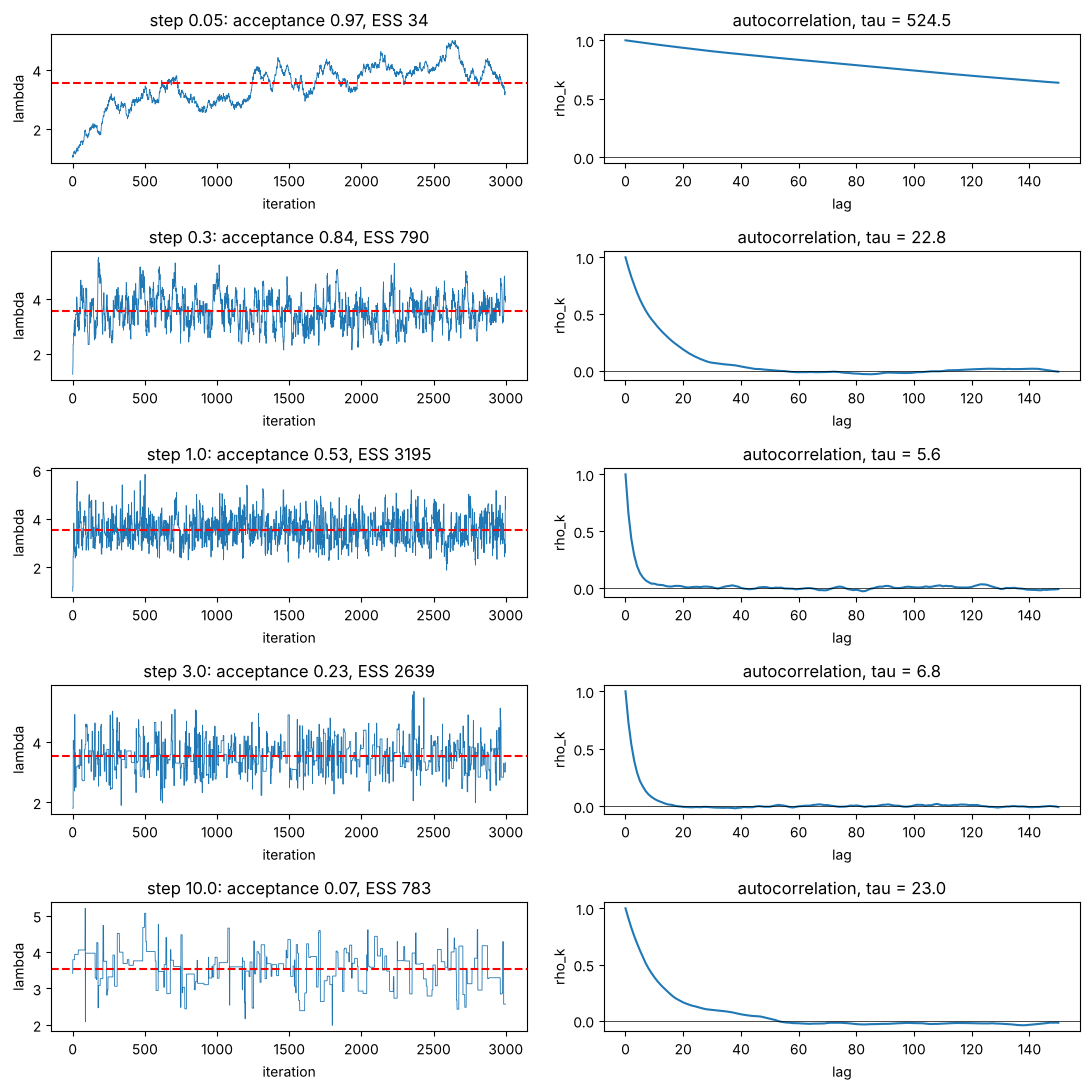


  step  accept    mean      sd     tau     ESS   (exact mean 3.5455, sd 0.5677)
  0.05   0.970  3.5287  0.5861   524.5      34
  0.30   0.838  3.5696  0.5801    22.8     790
  1.00   0.530  3.5483  0.5689     5.6    3195
  3.00   0.226  3.5420  0.5755     6.8    2639
 10.00   0.070  3.5446  0.5859    23.0     783

best step by ESS: 1.0  (acceptance 0.53; optimal step ~ 2.4 * posterior sd = 1.36)


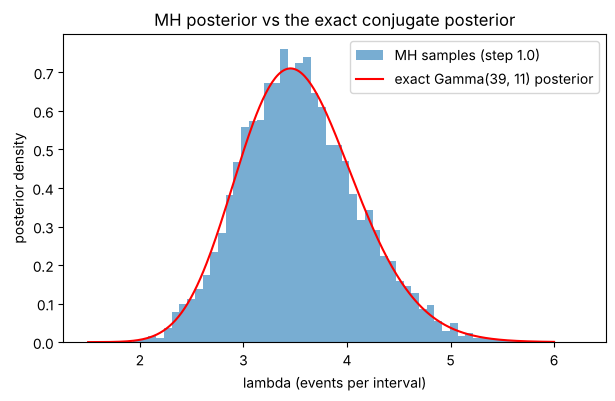

2.5%, 50%, 97.5% quantiles:  MH [2.505 3.513 4.759]   exact [2.521 3.515 4.742]
P(lambda > 4 | data):  MH 0.2052 +/- 0.0071 (MC error from the ESS)   exact 0.2056

small step 0.05 from lambda = 1: mean of iterations 1-200 = 1.715, of 2000-20000 = 3.529  (exact 3.545) -> burn-in is essential
R-hat over 4 chains (step 1.0): 1.0014  (values near 1.00 indicate the chains agree)


In [19]:
rng = np.random.default_rng(2024)
y = np.array([3, 5, 2, 4, 6, 3, 4, 5, 2, 3])
n, S = len(y), y.sum()
a0, b0 = 2.0, 1.0                                   # Gamma(shape 2, rate 1) prior on the rate lambda
a_post, b_post = a0 + S, b0 + n                     # exact conjugate posterior Gamma(39, 11)
print(f"data: n = {n}, sum = {S};  exact posterior Gamma(shape {a_post:.0f}, rate {b_post:.0f}): mean {a_post / b_post:.4f}, sd {np.sqrt(a_post) / b_post:.4f}")

def log_post(lam):
    # log prior + log likelihood, up to a constant; Poisson likelihood sum(y) log lam - n lam
    if lam <= 0:
        return -np.inf
    return (a0 - 1) * np.log(lam) - b0 * lam + S * np.log(lam) - n * lam

def random_walk_mh(log_target, x0, step, n_iter, rng):
    x, lp = float(x0), log_target(x0)
    chain, n_acc = np.empty(n_iter), 0
    for i in range(n_iter):
        prop = x + step * rng.standard_normal()
        lp_prop = log_target(prop)
        if np.log(rng.random()) < lp_prop - lp:
            x, lp, n_acc = prop, lp_prop, n_acc + 1
        chain[i] = x
    return chain, n_acc / n_iter

def autocorr(x, max_lag):
    x = x - x.mean(); d = x @ x
    return np.array([x[:len(x) - k] @ x[k:] / d for k in range(max_lag + 1)])

def ess(x, max_lag=1000):
    rho = autocorr(x, min(max_lag, len(x) - 1)); tau = 1.0
    for k in range(1, len(rho)):
        if rho[k] < 0:
            break
        tau += 2 * rho[k]
    return len(x) / tau, tau

n_iter, burn = 20_000, 2_000
steps = [0.05, 0.3, 1.0, 3.0, 10.0]
results = {}
fig, axes = plt.subplots(len(steps), 2, figsize=(11, 2.2 * len(steps)))
grid = np.linspace(1.5, 6.0, 300)
for row, s in enumerate(steps):
    chain, acc = random_walk_mh(log_post, 1.0, s, n_iter, rng)       # deliberately poor start at lambda = 1
    post = chain[burn:]
    n_eff, tau = ess(post)
    results[s] = dict(acc=acc, mean=post.mean(), sd=post.std(), ess=n_eff, tau=tau, chain=chain)
    axes[row, 0].plot(chain[:3000], lw=0.6); axes[row, 0].axhline(a_post / b_post, color="r", ls="--")
    axes[row, 0].set_title(f"step {s}: acceptance {acc:.2f}, ESS {n_eff:.0f}"); axes[row, 0].set_xlabel("iteration"); axes[row, 0].set_ylabel("lambda")
    axes[row, 1].plot(autocorr(post, 150)); axes[row, 1].axhline(0, color="k", lw=0.5)
    axes[row, 1].set_title(f"autocorrelation, tau = {tau:.1f}"); axes[row, 1].set_xlabel("lag"); axes[row, 1].set_ylabel("rho_k")
plt.tight_layout(); plt.show()

print(f"\n{'step':>6s} {'accept':>7s} {'mean':>7s} {'sd':>7s} {'tau':>7s} {'ESS':>7s}   (exact mean {a_post / b_post:.4f}, sd {np.sqrt(a_post) / b_post:.4f})")
for s in steps:
    r = results[s]
    print(f"{s:6.2f} {r['acc']:7.3f} {r['mean']:7.4f} {r['sd']:7.4f} {r['tau']:7.1f} {r['ess']:7.0f}")
best = max(steps, key=lambda s: results[s]["ess"])
print(f"\nbest step by ESS: {best}  (acceptance {results[best]['acc']:.2f}; optimal step ~ 2.4 * posterior sd = {2.4 * np.sqrt(a_post) / b_post:.2f})")

# compare the best chain with the exact posterior
post = results[best]["chain"][burn:]
plt.hist(post, bins=60, density=True, alpha=0.6, label=f"MH samples (step {best})")
plt.plot(grid, stats.gamma.pdf(grid, a_post, scale=1 / b_post), "r", label="exact Gamma(39, 11) posterior")
plt.xlabel("lambda (events per interval)"); plt.ylabel("posterior density"); plt.title("MH posterior vs the exact conjugate posterior"); plt.legend(); plt.show()
q_mc = np.quantile(post, [0.025, 0.5, 0.975]); q_ex = stats.gamma.ppf([0.025, 0.5, 0.975], a_post, scale=1 / b_post)
print("2.5%, 50%, 97.5% quantiles:  MH", q_mc.round(3), "  exact", q_ex.round(3))
print(f"P(lambda > 4 | data):  MH {np.mean(post > 4):.4f} +/- {np.sqrt(np.mean(post > 4) * (1 - np.mean(post > 4)) / results[best]['ess']):.4f} (MC error from the ESS)   exact {stats.gamma.sf(4, a_post, scale=1 / b_post):.4f}")

# burn-in matters when the start is bad: compare the first 200 iterations of the small-step chain with the posterior mean
bad = results[0.05]["chain"]
print(f"\nsmall step 0.05 from lambda = 1: mean of iterations 1-200 = {bad[:200].mean():.3f}, of 2000-20000 = {bad[2000:].mean():.3f}  (exact {a_post / b_post:.3f}) -> burn-in is essential")

# R-hat from 4 chains with dispersed starts, for the best step
chains = np.array([random_walk_mh(log_post, x0, best, 5_000, rng)[0][500:] for x0 in (0.5, 2.0, 5.0, 9.0)])
m_c, n_c = chains.shape
W = chains.var(axis=1, ddof=1).mean(); B = n_c * chains.mean(axis=1).var(ddof=1)
var_hat = (n_c - 1) / n_c * W + B / n_c
print(f"R-hat over 4 chains (step {best}): {np.sqrt(var_hat / W):.4f}  (values near 1.00 indicate the chains agree)")

## Score

In [20]:
summary()


Score: 58/58 checks passed  🎉
